In [363]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm
from scipy.stats import ks_2samp, bootstrap, ecdf
%matplotlib inline

In [58]:
user_home_meta = pd.read_parquet("/glade/campaign/cisl/aiml/cat_flood/user_home_loc_filter_5_30_base_2_ar.parquet")

In [184]:
user_home_meta

,duration,lat,lng,zipcode,row_group,county,distance_straight_line_quantile_2024-03-30,distance_straight_line_quantile_2024-03-31
uid,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,21 days 11:29:35,34.099681,-117.846496,91724,0,LA,0.972222,0.222222
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,4 days 23:15:49,34.107017,-118.200225,90042,0,LA,0.264706,0.029412
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,20 days 17:17:15,33.834393,-118.162468,90712,1,LA,0.340909,0.272727
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,25 days 17:41:43,34.034570,-118.127688,91755,3,LA,0.897436,0.538462
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,41 days 11:56:17,34.105705,-118.328606,90068,4,LA,0.162162,0.702703
...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,7 days 22:27:10,34.442840,-118.455062,91351,75005,LA,0.657143,0.428571
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,19 days 14:55:20,33.843157,-118.085274,90715,75007,LA,0.147059,0.264706
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,8 days 01:34:55,34.609001,-120.108748,93463,75010,SB,0.628571,0.514286


In [60]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))

In [175]:
ar_files[62]

'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_2024-03-31_PST_chunked.parquet'

In [66]:
df_1 = pd.read_parquet(ar_files[-1])
df_1 = df_1.set_index("uid")

In [77]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_file = ar_files[0]
ar_date = ar_file.split("/")[-1].split("_")[1]
metric = 'distance_straight_line'
df_0 = pd.read_parquet(ar_file, columns=["uid", metric])
print(df_0)
df_0 = df_0.set_index("uid")
df_joined = user_home_meta.join(df_0)
new_col = f"{metric}_{ar_date}"
df_joined = df_joined.rename(columns={metric: new_col})
metric_cols = [new_col]
for ar_file in tqdm(ar_files[1:]):
    ar_date = ar_file.split("/")[-1].split("_")[1]
    df_l = pd.read_parquet(ar_file, columns=["uid", metric])
    df_l = df_l.set_index("uid")
    df_joined = df_joined.join(df_l)
    new_col = f"{metric}_{ar_date}"
    df_joined = df_joined.rename(columns={metric: f"{metric}_{ar_date}"})
    metric_cols.append(new_col)


                                                   uid  distance_straight_line
218  0000ba15f25930f0a4ad2bd7114a40bd30a14214b245a8...               10.133705
248  0000a843eb75661d74cd9ba58f6830a1f84c5f49a0eac3...                0.000000
260  0000a396879fd5767b3d146bfe8c854ea48c8e9a86b9f5...               23.544740
475  0000712fa93eae897b02b840ce7a3be2b9eb8b06b12c46...                1.356103
485  00006558db84477cda9278ba16d40cab37598b931ad2e1...                0.001101
..                                                 ...                     ...
10   fffff922ba116e91a1274046b2f7b158355940c5433bb7...                0.000000
37   ffffe79bdb634159d1e5d074c662e2336fe012548ed571...               33.708051
280  ffffc189a959d16f168dfb7f90ebf0355d8f1cfae1e797...                0.000000
336  ffffacf186455724eff8a4c113f92378a24f2a6fa25d5d...                8.636476
438  ffff97a36ca183fdb6881a11e40251e572f38c4c69d7d5...                5.444928

[681854 rows x 2 columns]


100%|██████████| 91/91 [01:03<00:00,  1.43it/s]


(array([ 5048., 18921., 16419., 11297.,  6399.,  3394.,  1377.,   569.,
          381.,   299.,   310.,   739.]),
 array([30., 35., 40., 45., 50., 55., 60., 65., 70., 75., 80., 85., 90.]),
 <BarContainer object of 12 artists>)

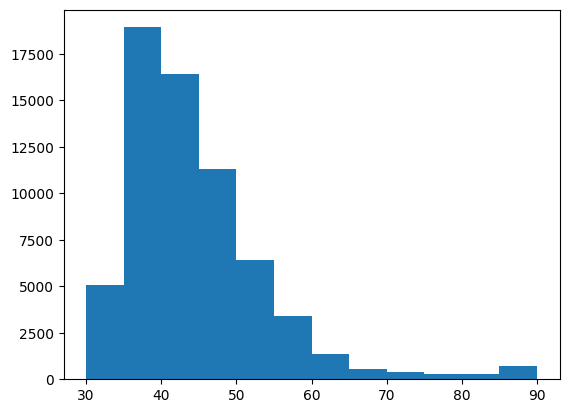

In [84]:
plt.hist(np.sum(~np.isnan(df_joined[metric_cols].values), axis=1), bins=np.arange(30, 95, 5))

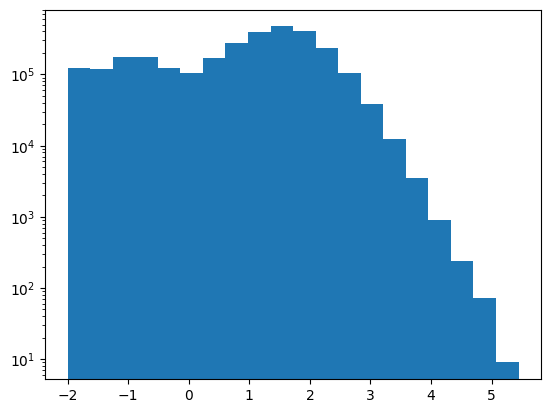

In [95]:
plt.hist(np.log10(np.maximum(df_joined[metric_cols].values.ravel(), 0.01)), bins=20)
plt.gca().set_yscale("log")

In [108]:
ar_event_dates = ["2024-03-29", "2024-03-30", "2024-03-31", "2024-04-01"]
ar_event_cols = [f"{metric}_{date}" for date in ar_event_dates]
baseline_flag = ~np.isin(metric_cols, ar_event_cols)
baseline_cols = pd.Series(metric_cols)[baseline_flag]
ar_event_flag = np.isin(metric_cols, ar_event_cols)

In [130]:
df_joined[baseline_cols]

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.577447,0.148050,0.072076,4.518701,4.157835,0.701545,10.297275,24.818907,0.115762,0.046051
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,27.763370,NaN,NaN,0.405339,37.286825,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.046567,0.022539,NaN,40.281856,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.020226,7.104384,38.966774,NaN,19.843855,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.789224,2.291767,1.353006,0.884060,0.178346,43.555438,1.450768,1.218656,113.242463,0.469914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.019192,0.070023,2.216624,3.955427,188.914653,53.337993,135.176858,1081.390252,516.811776,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.261490,15.068729,13.907677,NaN,NaN,NaN,NaN,0.083488,10.206489,8.337815
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,33.446894,NaN,3.285429,87.149954,1.710188,5.083226,NaN,NaN,104.336061,NaN


In [554]:
base_log_metric = np.log(np.maximum(df_joined[metric_cols], 0.1))
people_means = np.nanmean(base_log_metric, axis=1)
people_sds  = np.nanstd(base_log_metric, axis=1)
people_ns = np.count_nonzero(~np.isnan(base_log_metric), axis=1)
z_score = (base_log_metric[f"{metric}_2024-03-31"]  - people_means) / (people_sds)
z_score_samp = (base_log_metric[f"{metric}_2024-03-31"]  - people_means) / (people_sds/ np.sqrt(people_ns))

(array([15944., 21763., 13978.,  7264.,  3241.,  1037.,   511.,   366.,
          372.,  1366.]),
 array([32., 38., 44., 50., 56., 62., 68., 74., 80., 86., 92.]),
 <BarContainer object of 10 artists>)

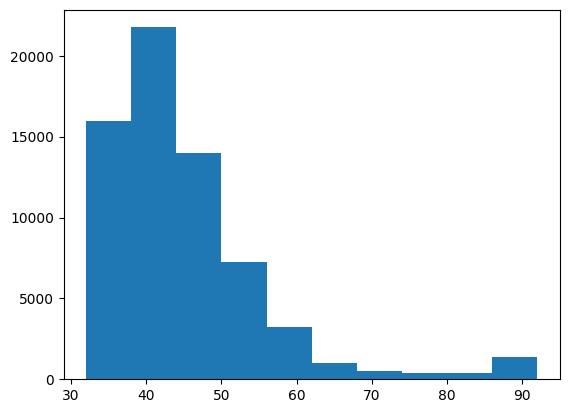

In [493]:
plt.hist(people_ns)

In [532]:
z_score_base = (base_log_metric - people_means.reshape(-1, 1)) / (people_sds.reshape(-1, 1))

In [506]:
dates = [x.split("_")[-1] for x in metric_cols]

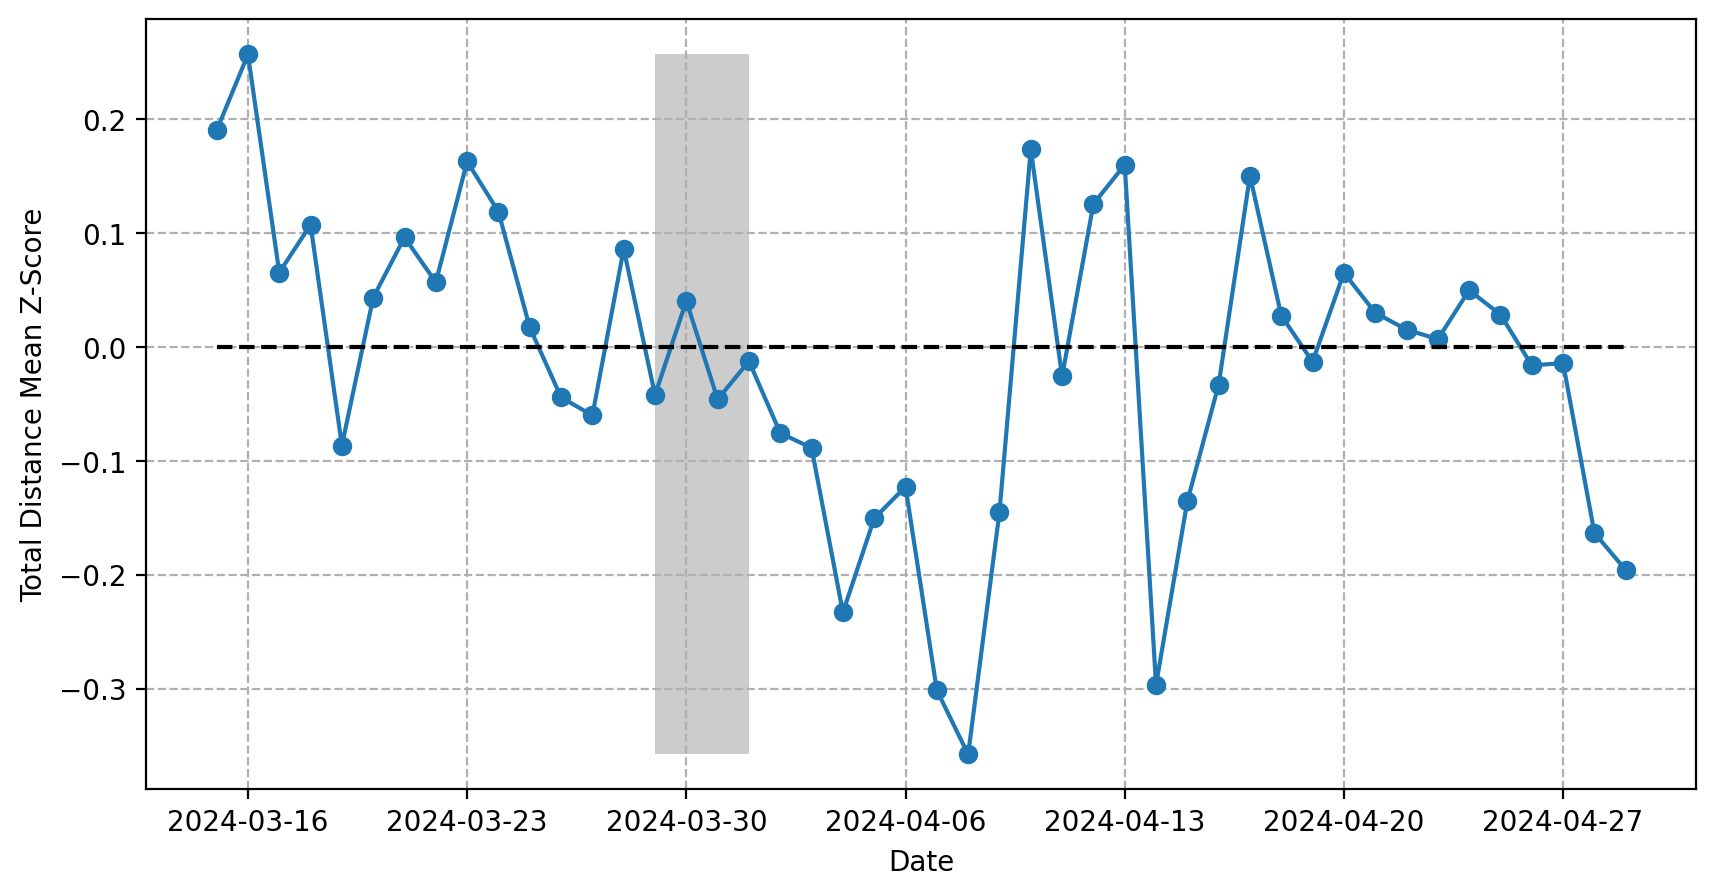

In [596]:
plt.figure(figsize=(10, 5), dpi=200)
z_trace = np.nanmean(z_score_base, axis=0)[46:]
d_idx = pd.DatetimeIndex(dates[46:])
plt.fill_between(pd.DatetimeIndex(["2024-03-29", "2024-04-01"]), z_trace.min(), z_trace.max(), fc='0.8')
plt.plot(d_idx, z_trace, marker='o')
plt.xlabel("Date")
plt.ylabel("Total Distance Mean Z-Score")
plt.plot(d_idx, np.zeros_like(z_trace), 'k--')
plt.xticks(d_idx[1::7])
plt.grid(ls='--')
plt.savefig("mean_dist_z_score.png", bbox_inches="tight")

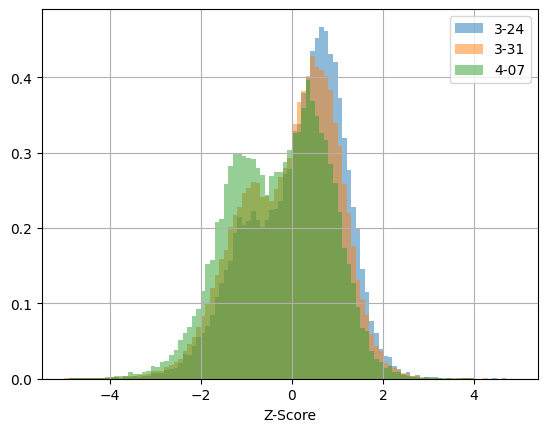

In [588]:
z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-03-24"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, label="3-24", alpha=0.5)
z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-03-31"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, label="3-31", alpha=0.5)
z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-04-07"].hist(bins=np.arange(-5, 5, 0.1), 
                                                                                   density=True, label="4-07", alpha=0.5)

plt.xlabel("Z-Score")
plt.legend()
plt.savefig("day_comp_hist.png", bbox_inches="tight")

In [581]:
ks_2samp(z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-03-19"].dropna(),
          z_score_base.loc[daily_ar_data_sub["county"] == "LA", f"{metric}_2024-03-26"].dropna())

KstestResult(statistic=np.float64(0.022080306557299312), pvalue=np.float64(1.1137756810223808e-09), statistic_location=np.float64(-0.4097621458741054), statistic_sign=np.int8(1))

In [529]:
z_score_base

,distance_straight_line_2023-03-15,distance_straight_line_2023-03-16,distance_straight_line_2023-03-17,distance_straight_line_2023-03-18,distance_straight_line_2023-03-19,distance_straight_line_2023-03-20,distance_straight_line_2023-03-21,distance_straight_line_2023-03-22,distance_straight_line_2023-03-23,distance_straight_line_2023-03-24,...,distance_straight_line_2024-04-20,distance_straight_line_2024-04-21,distance_straight_line_2024-04-22,distance_straight_line_2024-04-23,distance_straight_line_2024-04-24,distance_straight_line_2024-04-25,distance_straight_line_2024-04-26,distance_straight_line_2024-04-27,distance_straight_line_2024-04-28,distance_straight_line_2024-04-29
uid,,,,,,,,,,,,,,,,,,,,,
000093ca81930e1c247112fceaa58e2d2e3df3e1d438f68b75139d4daf3d6f99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.786118,-7.550158,-8.580745,1.428344,1.209740,-3.464022,3.591673,5.902274,-8.196311,-8.580745
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,2.719288,NaN,NaN,-8.511316,3.502906,NaN,NaN
00015ca877df61dd171b9ab468c2d7f2fcf2306b06a37177b57fca7e2283f6d4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-12.620528,-12.620528,NaN,4.136714,NaN,NaN,NaN,NaN
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,-14.229815,0.225861,5.996869,NaN,3.708756,NaN,NaN,NaN,NaN
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.967983,3.994486,1.809149,0.044440,-6.593751,16.205605,2.098445,1.375474,20.167855,-2.576232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fff5b42f30854c7b550a200e08e3cd6b6a0ed5175fef68f9068ade30cdba18de,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-11.889247,-11.889247,-5.348439,-4.126003,4.035217,1.365660,3.328671,7.718140,6.159603,NaN
fff6b7a9c79dc38d377a05321cc2a76aa9056526f3595c6366ff0373308bd8b9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-8.127484,4.104792,3.862859,NaN,NaN,NaN,NaN,-11.027839,2.929239,2.319063
fff98bbc3473005cbf05972bfcd09f750c72ffb9502920894cf2ea3abca4efcf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.708584,NaN,-3.037176,3.667193,-4.372461,-2.144560,NaN,NaN,4.035299,NaN


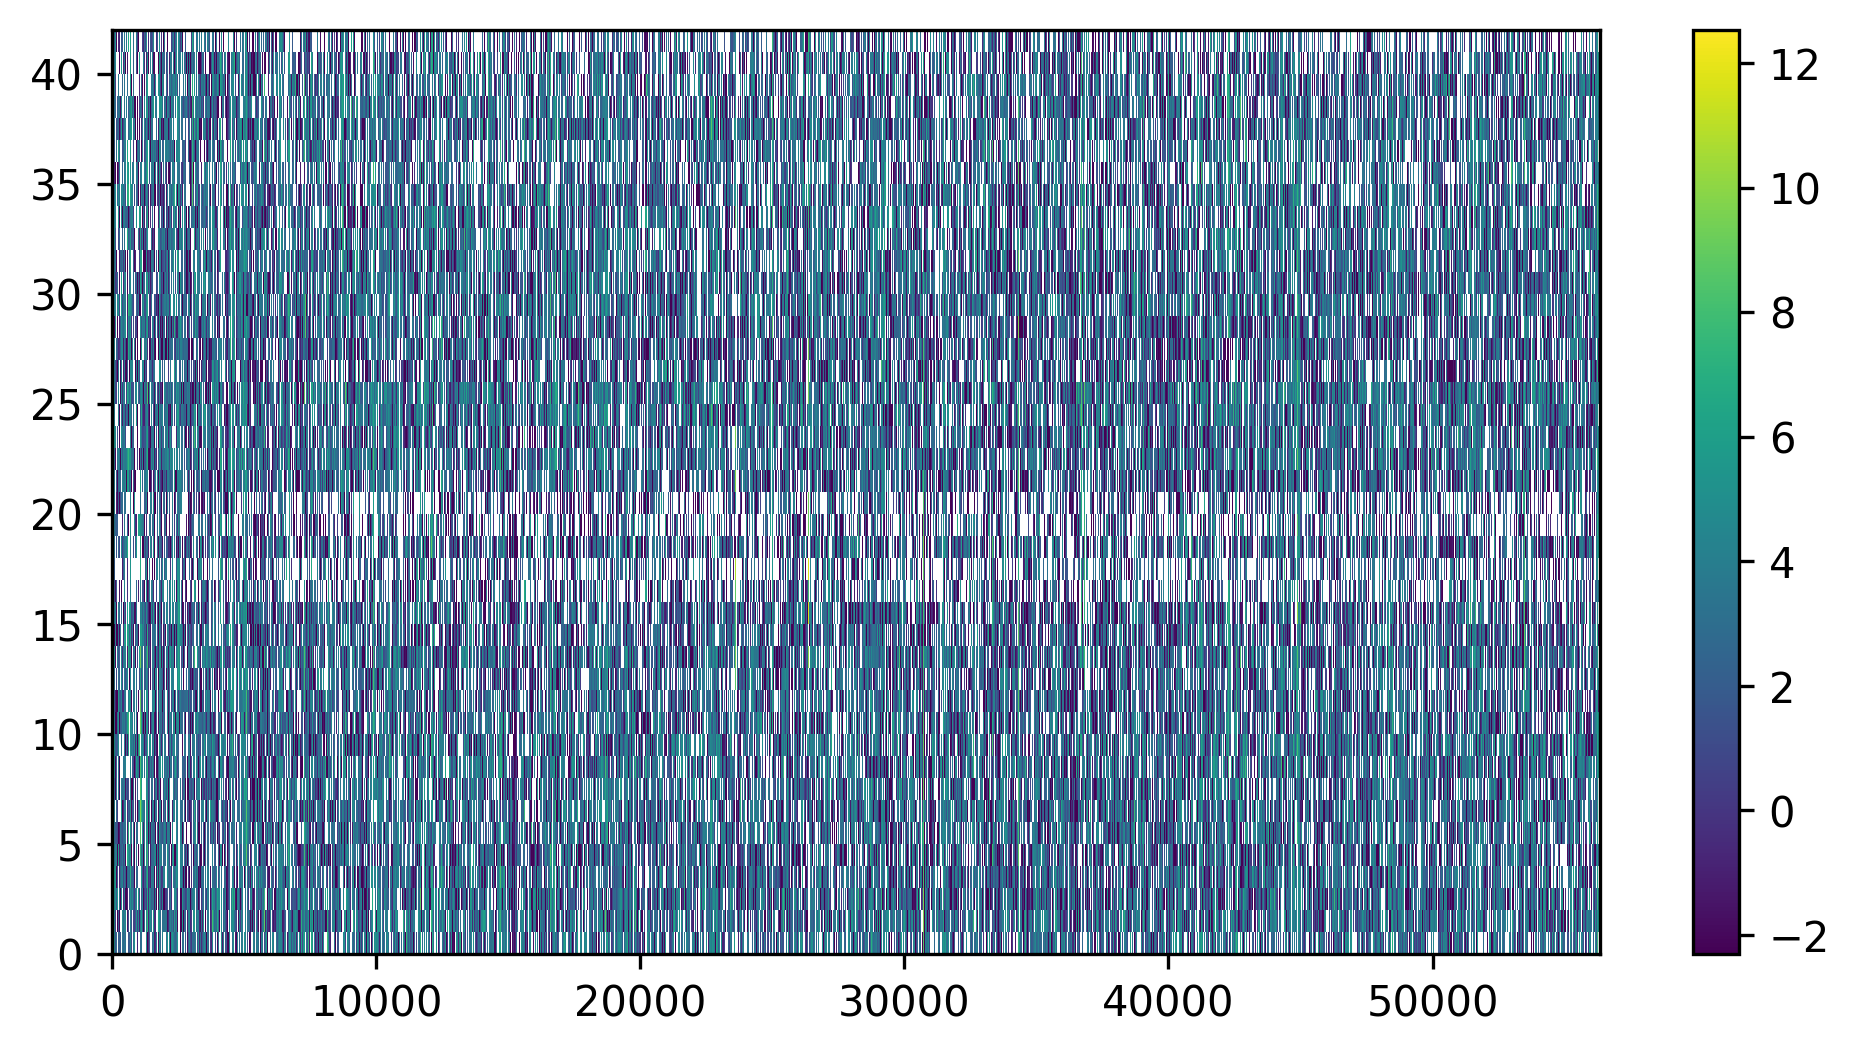

In [438]:
plt.figure(figsize=(8, 4), dpi=300)
plt.pcolormesh(base_log_metric[daily_ar_data_sub["county"] == "LA"].T)
plt.colorbar()

In [407]:
base_log_metric.columns[46:]

Index(['distance_straight_line_2024-03-15',
       'distance_straight_line_2024-03-16',
       'distance_straight_line_2024-03-17',
       'distance_straight_line_2024-03-18',
       'distance_straight_line_2024-03-19',
       'distance_straight_line_2024-03-20',
       'distance_straight_line_2024-03-21',
       'distance_straight_line_2024-03-22',
       'distance_straight_line_2024-03-23',
       'distance_straight_line_2024-03-24',
       'distance_straight_line_2024-03-25',
       'distance_straight_line_2024-03-26',
       'distance_straight_line_2024-03-27',
       'distance_straight_line_2024-03-28',
       'distance_straight_line_2024-04-02',
       'distance_straight_line_2024-04-03',
       'distance_straight_line_2024-04-04',
       'distance_straight_line_2024-04-05',
       'distance_straight_line_2024-04-06',
       'distance_straight_line_2024-04-07',
       'distance_straight_line_2024-04-08',
       'distance_straight_line_2024-04-09',
       'distance_straight_line_2

In [392]:
bs = bootstrap((z_score.values,), np.nanmean, n_resamples=1000, method="BCa")

In [393]:
bs

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(0.03209784110664471), high=np.float64(0.04844424750819935)), bootstrap_distribution=array([0.04106233, 0.04194987, 0.03888401, 0.0364238 , 0.03847973,
       0.04351092, 0.0384202 , 0.03521839, 0.04620036, 0.03995744,
       0.03791555, 0.03985   , 0.03652032, 0.03682268, 0.03601261,
       0.04816044, 0.03967103, 0.0421998 , 0.0436596 , 0.03931636,
       0.04257237, 0.03440642, 0.0495271 , 0.04058203, 0.0450426 ,
       0.04742216, 0.04249289, 0.03919391, 0.04465686, 0.03734185,
       0.04100984, 0.04182358, 0.03777691, 0.03282603, 0.04468792,
       0.03990097, 0.04158047, 0.03876044, 0.0361069 , 0.03712713,
       0.04376172, 0.04685037, 0.03644638, 0.03226929, 0.04006439,
       0.04123299, 0.03803659, 0.03952474, 0.0491623 , 0.04409111,
       0.04562419, 0.04620366, 0.03857167, 0.04208073, 0.02982926,
       0.03402334, 0.03557167, 0.04599584, 0.04479333, 0.03993047,
       0.04054459, 0.04402419, 0.04395312,

(array([ 1.,  0.,  1.,  1.,  3.,  6.,  5.,  7.,  5.,  5., 10., 14., 12.,
        17., 19., 29., 21., 26., 28., 32., 40., 42., 45., 51., 53., 45.,
        58., 37., 42., 42., 36., 46., 33., 31., 29., 27., 25., 15., 11.,
         7., 10.,  7.,  6.,  3.,  4.,  7.,  2.,  0.,  1.,  3.]),
 array([0.01764728, 0.01813943, 0.01863158, 0.01912373, 0.01961588,
        0.02010803, 0.02060018, 0.02109233, 0.02158448, 0.02207663,
        0.02256878, 0.02306093, 0.02355308, 0.02404523, 0.02453738,
        0.02502954, 0.02552169, 0.02601384, 0.02650599, 0.02699814,
        0.02749029, 0.02798244, 0.02847459, 0.02896674, 0.02945889,
        0.02995104, 0.03044319, 0.03093534, 0.03142749, 0.03191964,
        0.03241179, 0.03290394, 0.03339609, 0.03388824, 0.03438039,
        0.03487254, 0.03536469, 0.03585684, 0.036349  , 0.03684115,
        0.0373333 , 0.03782545, 0.0383176 , 0.03880975, 0.0393019 ,
        0.03979405, 0.0402862 , 0.04077835, 0.0412705 , 0.04176265,
        0.0422548 ]),
 <BarContainer

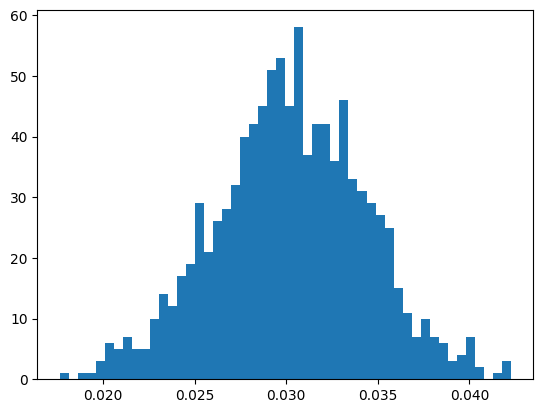

In [383]:
plt.hist(bs.bootstrap_distribution, bins=50)

In [370]:
bs

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(-0.0659727750035373), high=np.float64(-0.04916771285922762)), bootstrap_distribution=array([-0.05930468, -0.06029576, -0.04914075, ..., -0.06158853,
       -0.05801913, -0.05736117], shape=(10000,)), standard_error=np.float64(0.004326126533701763))

In [384]:
1 - ecdf(bs.bootstrap_distribution).cdf.evaluate(0)

np.float64(1.0)

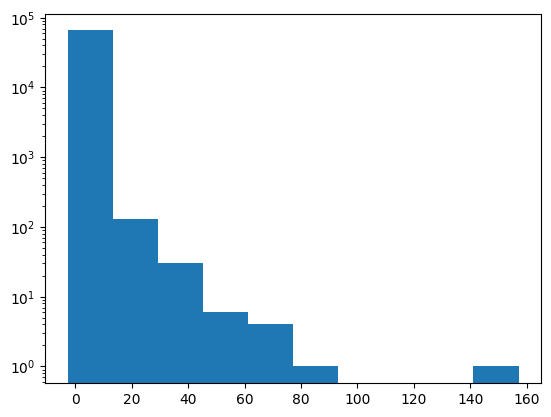

In [343]:
plt.hist(z_score)
plt.gca().set_yscale("log")

In [310]:
m_date = "2024-03-30"
m_col = f"{metric}_{m_date}"
good_vals = np.count_nonzero(~np.isnan(df_joined[baseline_cols.values]), axis=1)
metric_quantiles = ((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1)[m_col] - 1) / good_vals)

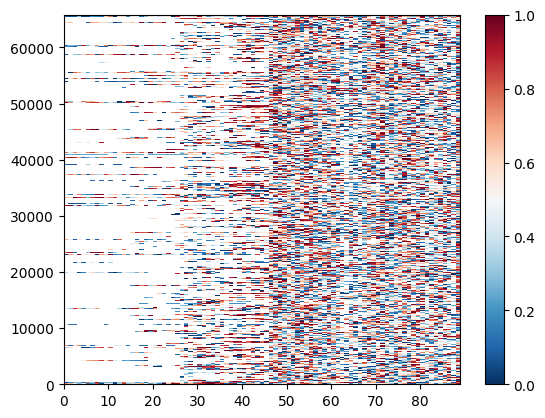

In [309]:
plt.pcolormesh((df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1).values -1) / good_vals.reshape(-1, 1), cmap="RdBu_r")
plt.colorbar()

In [306]:
np.nanmax(df_joined[baseline_cols.tolist() + [m_col]].rank(axis=1).values)

np.float64(89.0)

In [308]:
good_vals.min()

np.int64(28)

In [312]:
user_home_meta[m_col] = metric_quantiles

county
LA    Axes(0.125,0.11;0.775x0.77)
SB    Axes(0.125,0.11;0.775x0.77)
VE    Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

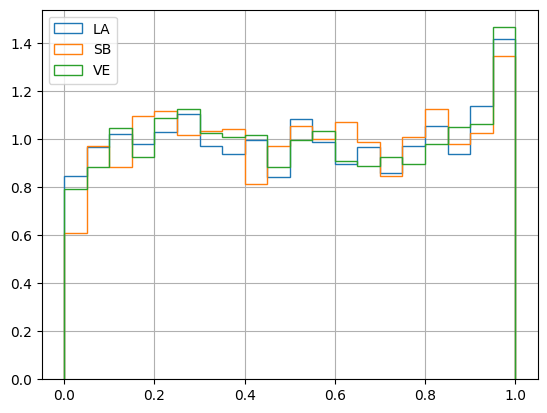

In [313]:
user_home_meta.groupby("county")[m_col].hist(bins=20, 
                                            histtype="step", density=True, 
                                            legend=True)


In [252]:
ar_mrms_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_*.parquet"))

In [187]:
ar_mrms_files

['/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-27_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-28_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-29_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-30_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-03-31_PST_chunked.parquet',
 '/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_2024-04-01_PST_chunked.parquet']

In [314]:
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
daily_ar_data_sub = daily_ar_data.loc[user_home_meta.index]

<Axes: >

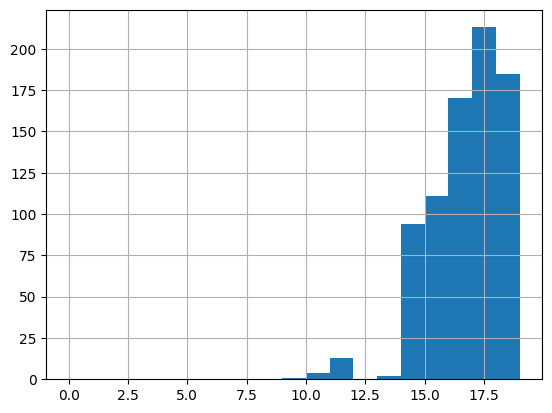

In [316]:
daily_ar_data_sub["precip_sum"].hist(bins=np.arange(0, 20))
#plt.gca().set_yscale('log')

In [317]:
daily_ar_data_sub.columns

Index(['duration', 'lat_home', 'lng_home', 'zipcode', 'row_group', 'county',
       'number_of_visits', 'distance_straight_line', 'jump_lengths',
       'radius_of_gyration', 'num_stops', 'max_distance_from_home', 'date',
       'FFW', 'precip_max', 'precip_sum', 'streamflow_max', 'streamflow_sum',
       'distance_straight_line_2024-03-30', 'streamflow_max_flag',
       'precip_sum_flag', 'precip_max_flag'],
      dtype='object')

In [323]:
daily_ar_data_sub[m_col] = metric_quantiles
daily_ar_data_sub["streamflow_max_flag"] = daily_ar_data_sub["streamflow_max"] >= 4
daily_ar_data_sub["precip_sum_flag"] = daily_ar_data_sub["precip_sum"] >= 16
daily_ar_data_sub["precip_max_flag"] = daily_ar_data_sub["precip_max"] >= 5

precip_sum_flag
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

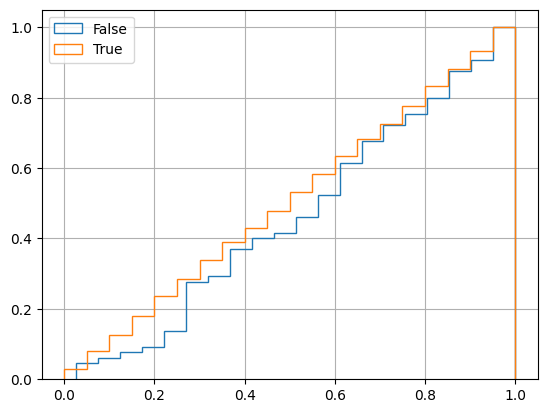

In [326]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "SB"].groupby("precip_sum_flag")[m_col].hist(bins=20, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=True)


FFW
False    Axes(0.125,0.11;0.775x0.77)
True     Axes(0.125,0.11;0.775x0.77)
Name: distance_straight_line_2024-03-30, dtype: object

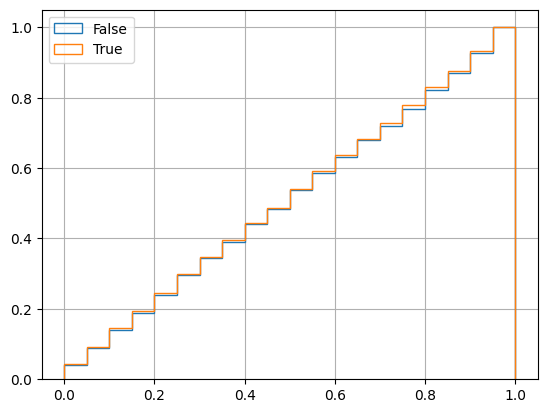

In [328]:
daily_ar_data_sub[daily_ar_data_sub["county"] == "LA"].groupby("FFW")[m_col].hist(bins=20, 
                                                                        histtype="step", density=True, 
                                                                        legend=True, cumulative=True)

In [334]:
ks_2samp(metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")], 
         metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")])

KstestResult(statistic=np.float64(0.011448834853090117), pvalue=np.float64(0.0522948944039513), statistic_location=np.float64(0.7837837837837838), statistic_sign=np.int8(1))

<Axes: >

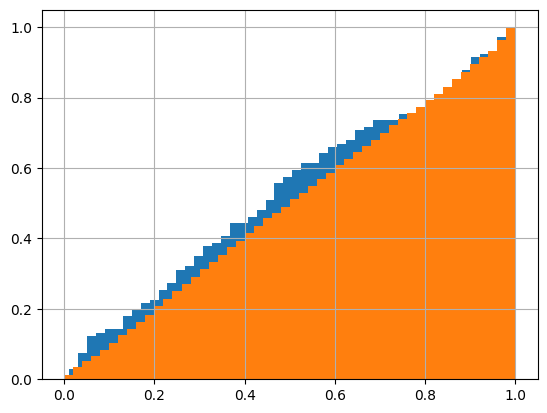

In [330]:
metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")].hist(density=True,cumulative=True, bins=50)
metric_quantiles[(~daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "VE")].hist(density=True, cumulative=True, bins=50)

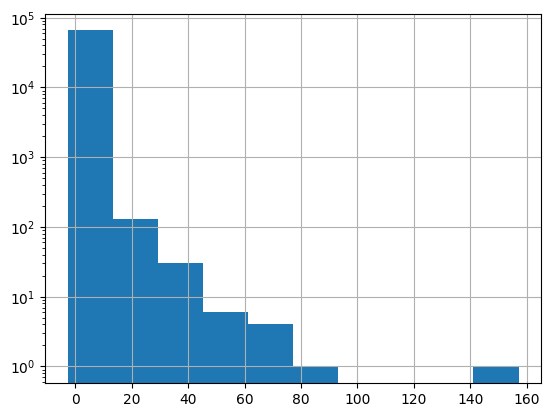

In [129]:
z_score.hist()
plt.gca().set_yscale("log")

In [57]:
df_1["uid"].unique().size

681854

In [56]:
df_1["uid"].shape

(681854,)

In [377]:
bootstrap((metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "SB")],), 
          np.mean)

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(0.49047559655721973), high=np.float64(0.5311955288748615)), bootstrap_distribution=array([0.50875714, 0.53212751, 0.51743481, ..., 0.52826157, 0.49131366,
       0.52710399], shape=(9999,)), standard_error=np.float64(0.010337790670502976))

In [340]:
metric_quantiles[(daily_ar_data_sub["FFW"]) & (daily_ar_data_sub["county"] == "LA")].values

array([0.23529412, 0.31818182, 0.13513514, ..., 0.96774194, 0.69318182,
       0.7       ], shape=(24675,))